In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df["Revenue"].value_counts())

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

Missing values:
Administrative      

In [10]:
numeric_columns = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

categorical_columns = [
    'Month',
    'OperatingSystems',
    'Browser',
    'Region',
    'TrafficType',
    'VisitorType',
    'Weekend'
]

target_column = 'Revenue'

In [11]:
print("Number of numerical columns:", len(numeric_columns))
print("Number of categorical columns:", len(categorical_columns))

Number of numerical columns: 10
Number of categorical columns: 7


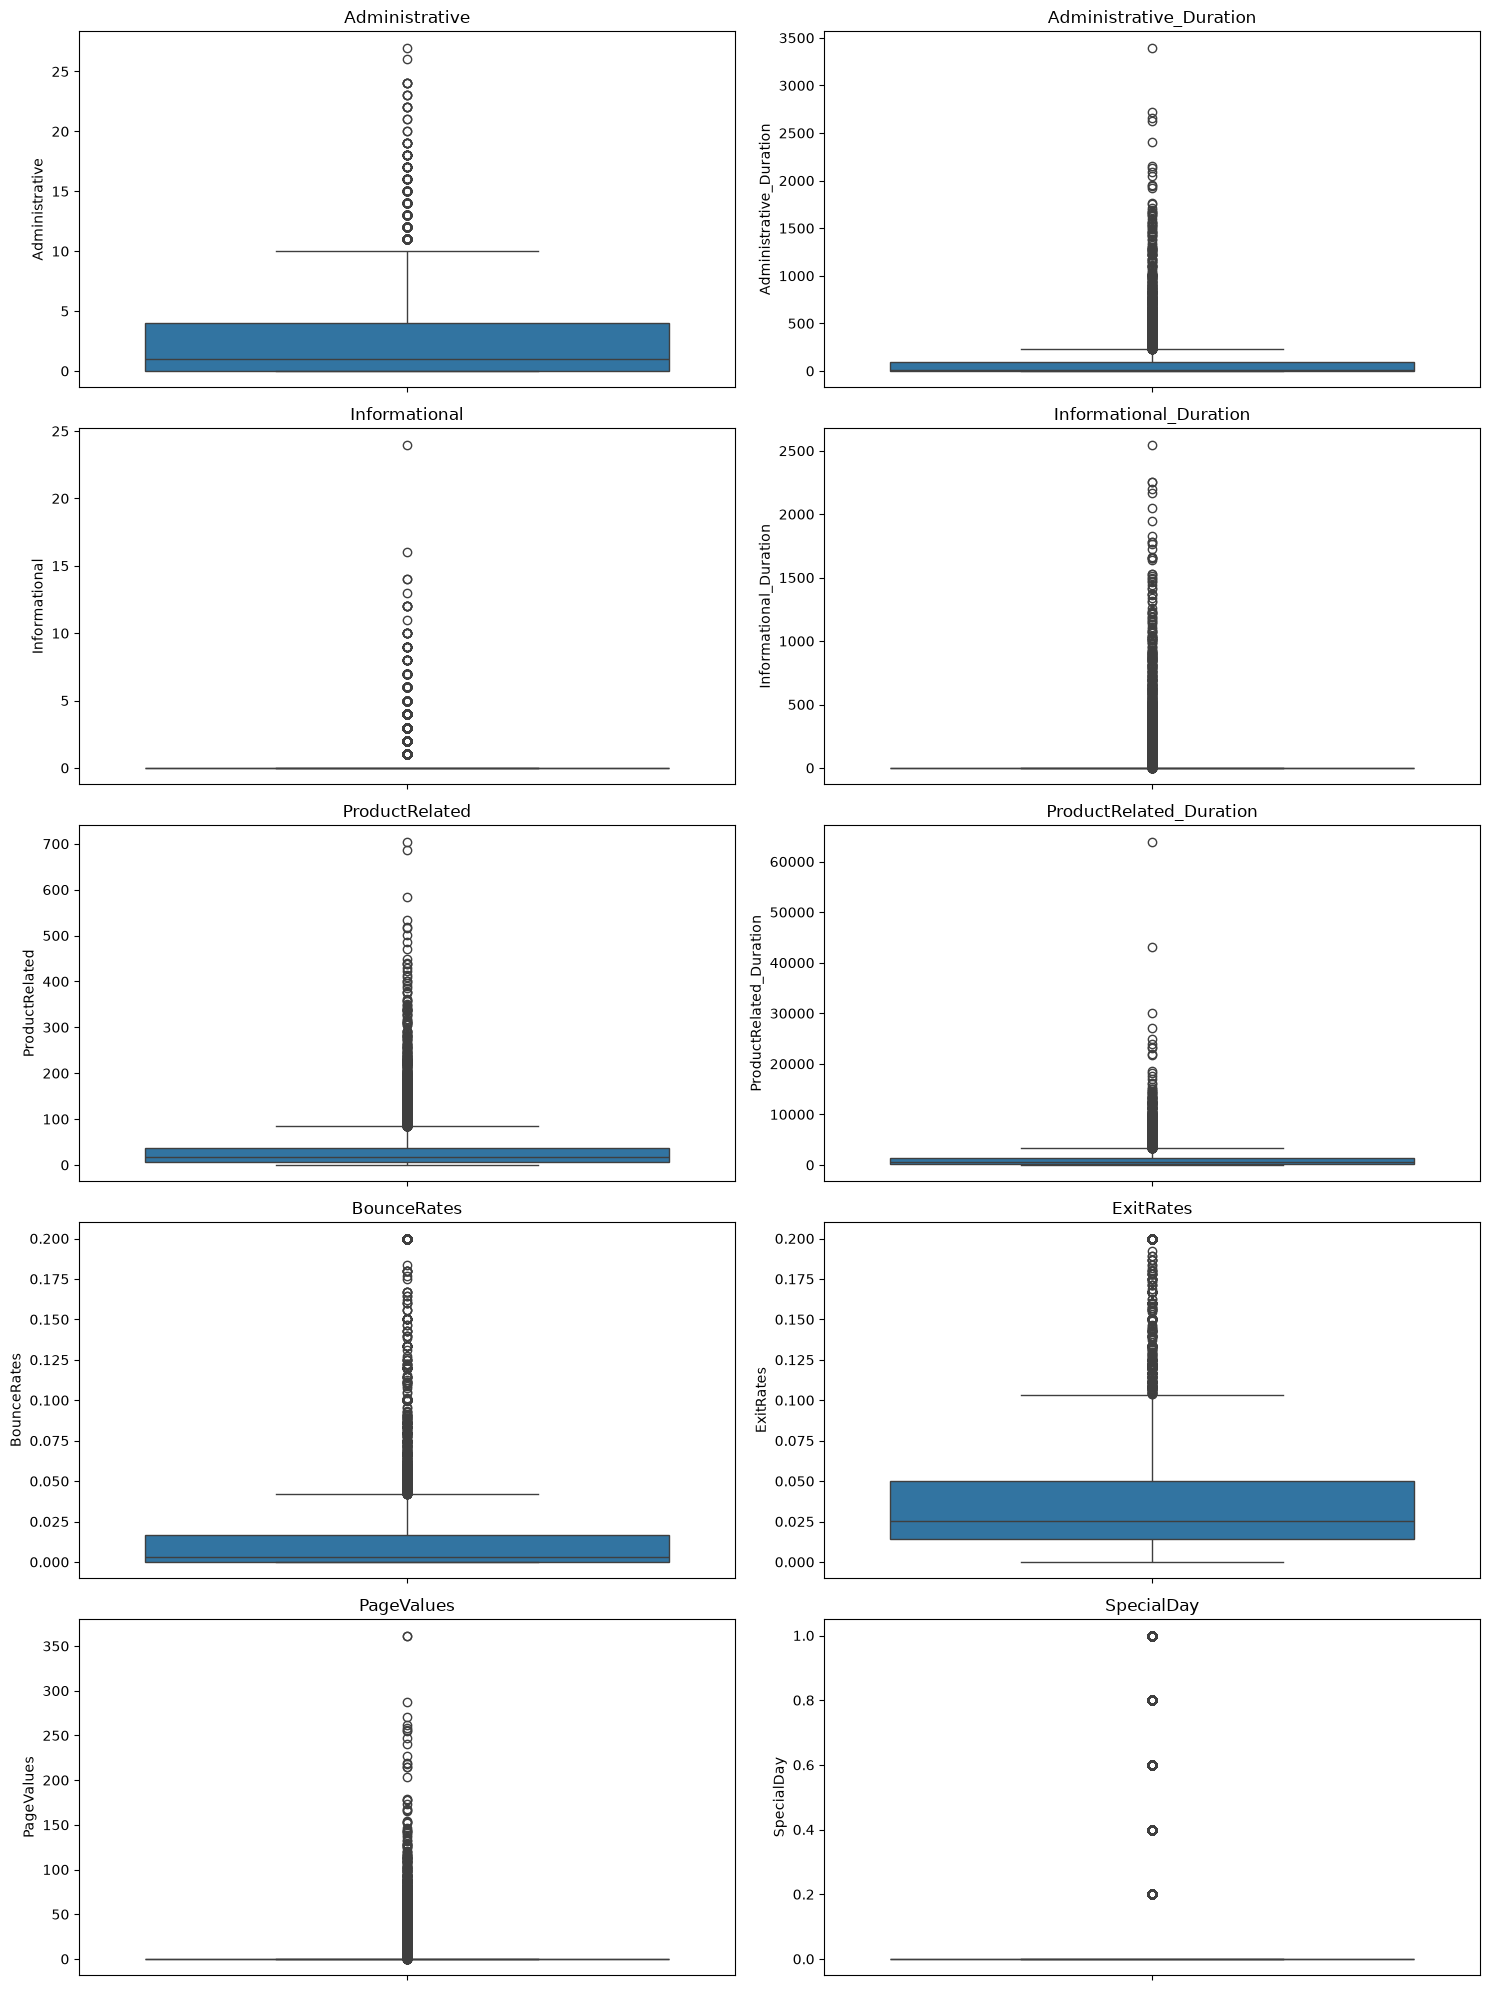

In [13]:

plt.figure(figsize=(15, 20))

for i, col in enumerate(numeric_columns):
    plt.subplot(5, 2, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [14]:
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

Administrative: 404 outliers
Administrative_Duration: 1172 outliers
Informational: 2631 outliers
Informational_Duration: 2405 outliers
ProductRelated: 987 outliers
ProductRelated_Duration: 961 outliers
BounceRates: 1551 outliers
ExitRates: 1099 outliers
PageValues: 2730 outliers
SpecialDay: 1251 outliers


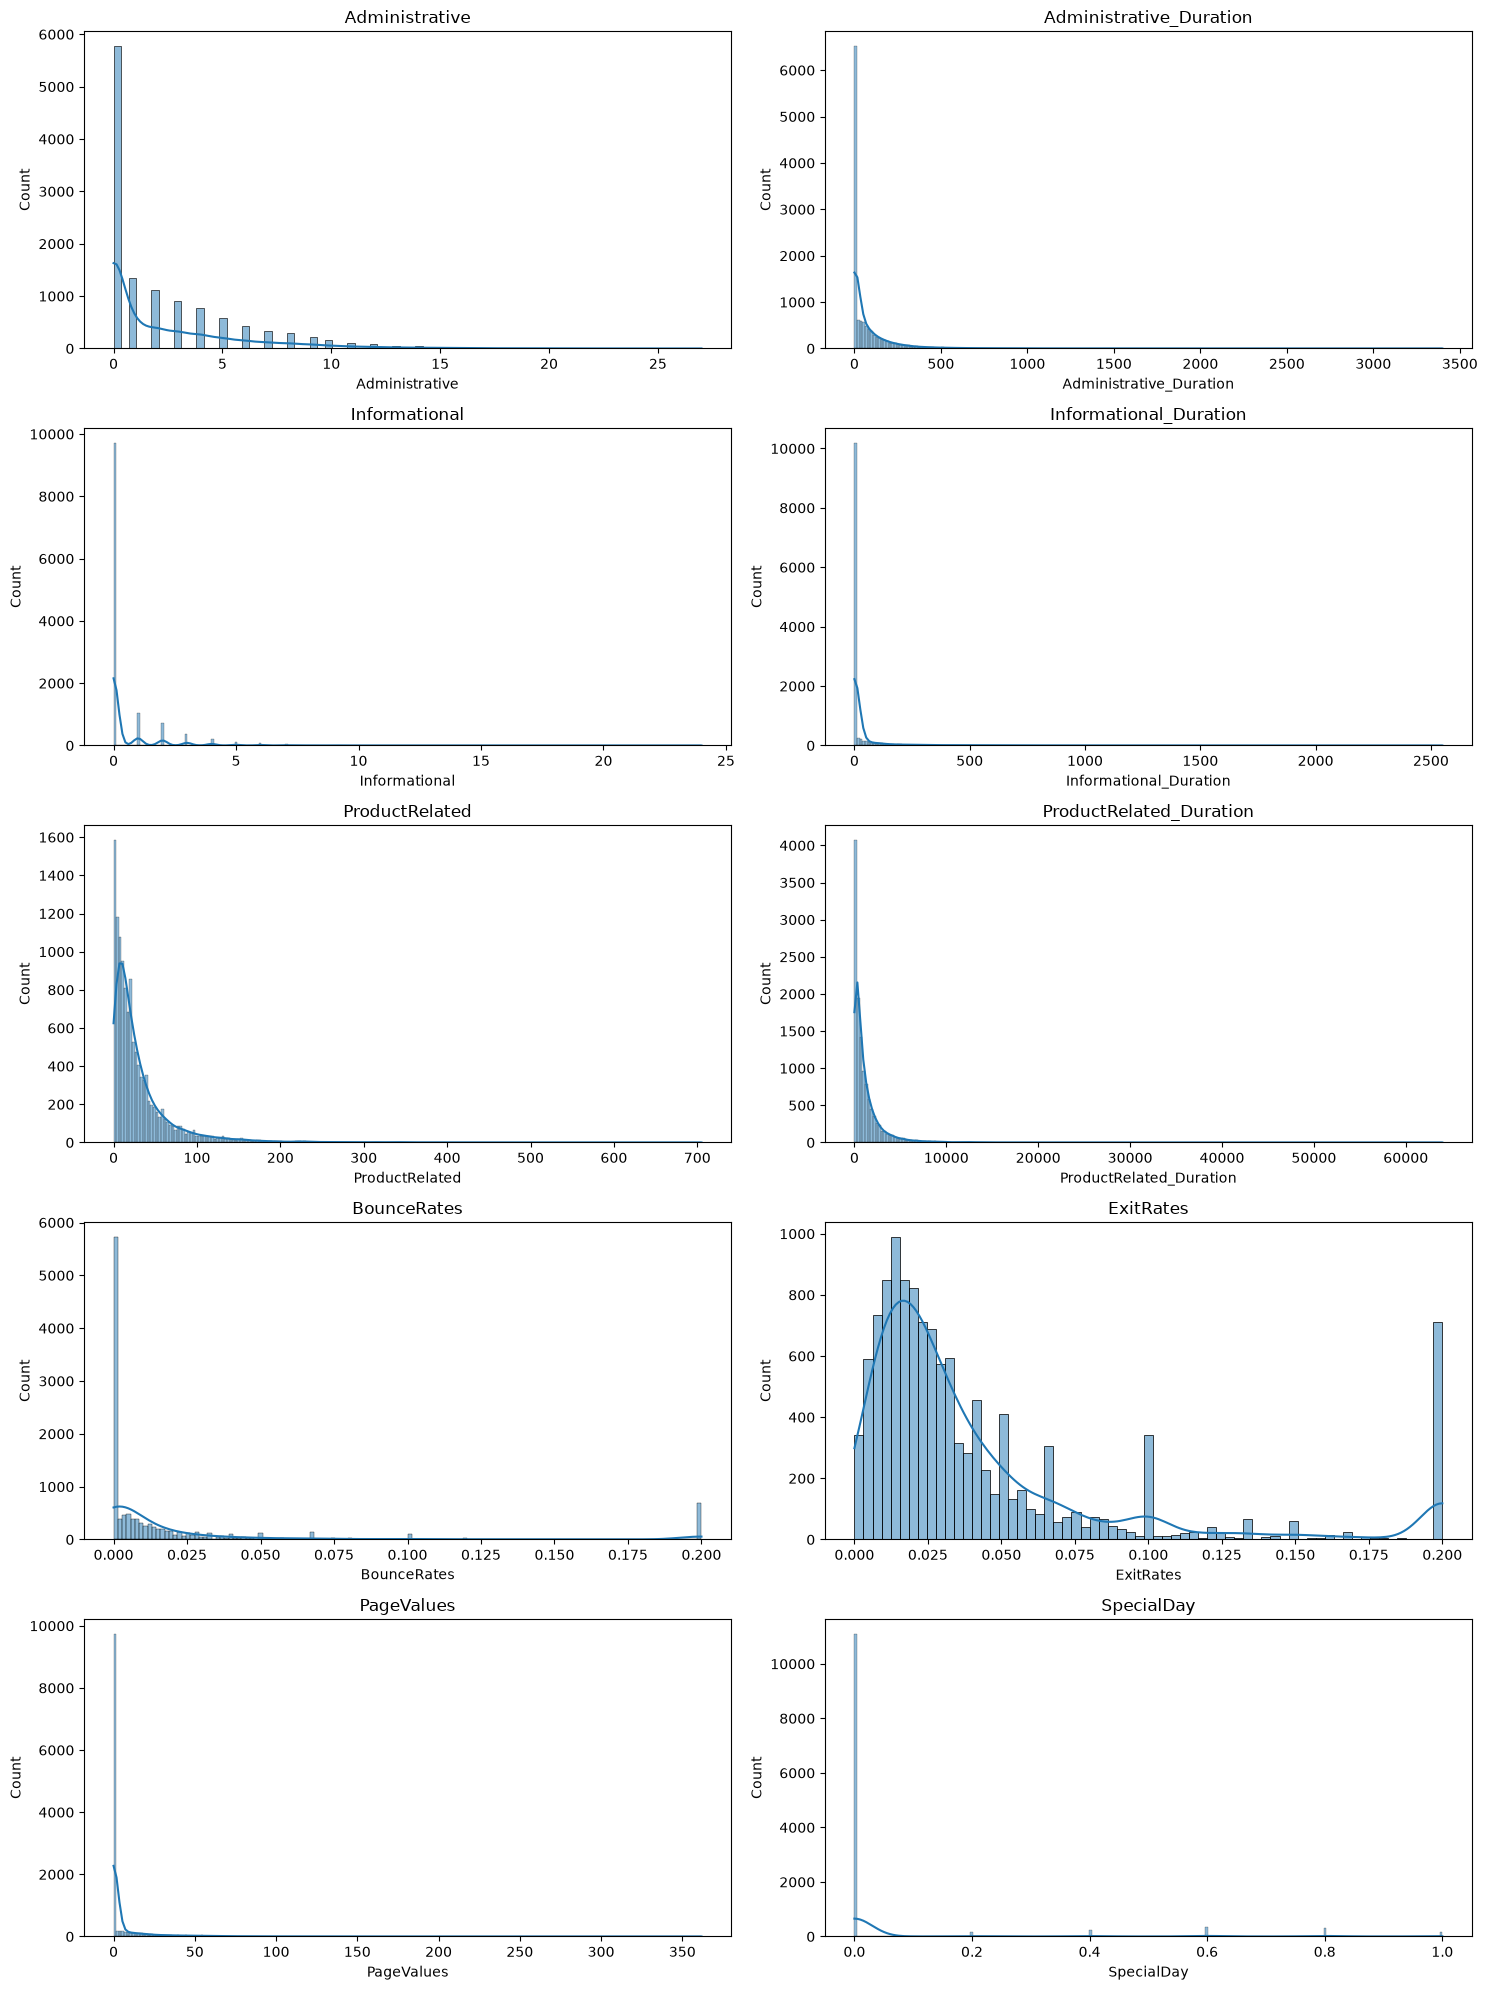

In [22]:
fig, axes = plt.subplots(5, 2, figsize=(15, 20))

for ax, col in zip(axes.flatten(), numeric_columns):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [23]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [24]:
df = df.drop_duplicates()

In [26]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.750000
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.522230
BounceRates,12205.0,0.020370,0.045255,0.0,0.000000,0.002899,0.016667,0.200000
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.200000
PageValues,12205.0,5.949574,18.653671,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12205.0,0.061942,0.199666,0.0,0.000000,0.000000,0.000000,1.000000


In [27]:
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

Administrative: 404 outliers
Administrative_Duration: 1149 outliers
Informational: 2631 outliers
Informational_Duration: 2405 outliers
ProductRelated: 1007 outliers
ProductRelated_Duration: 951 outliers
BounceRates: 1428 outliers
ExitRates: 1325 outliers
PageValues: 2730 outliers
SpecialDay: 1249 outliers


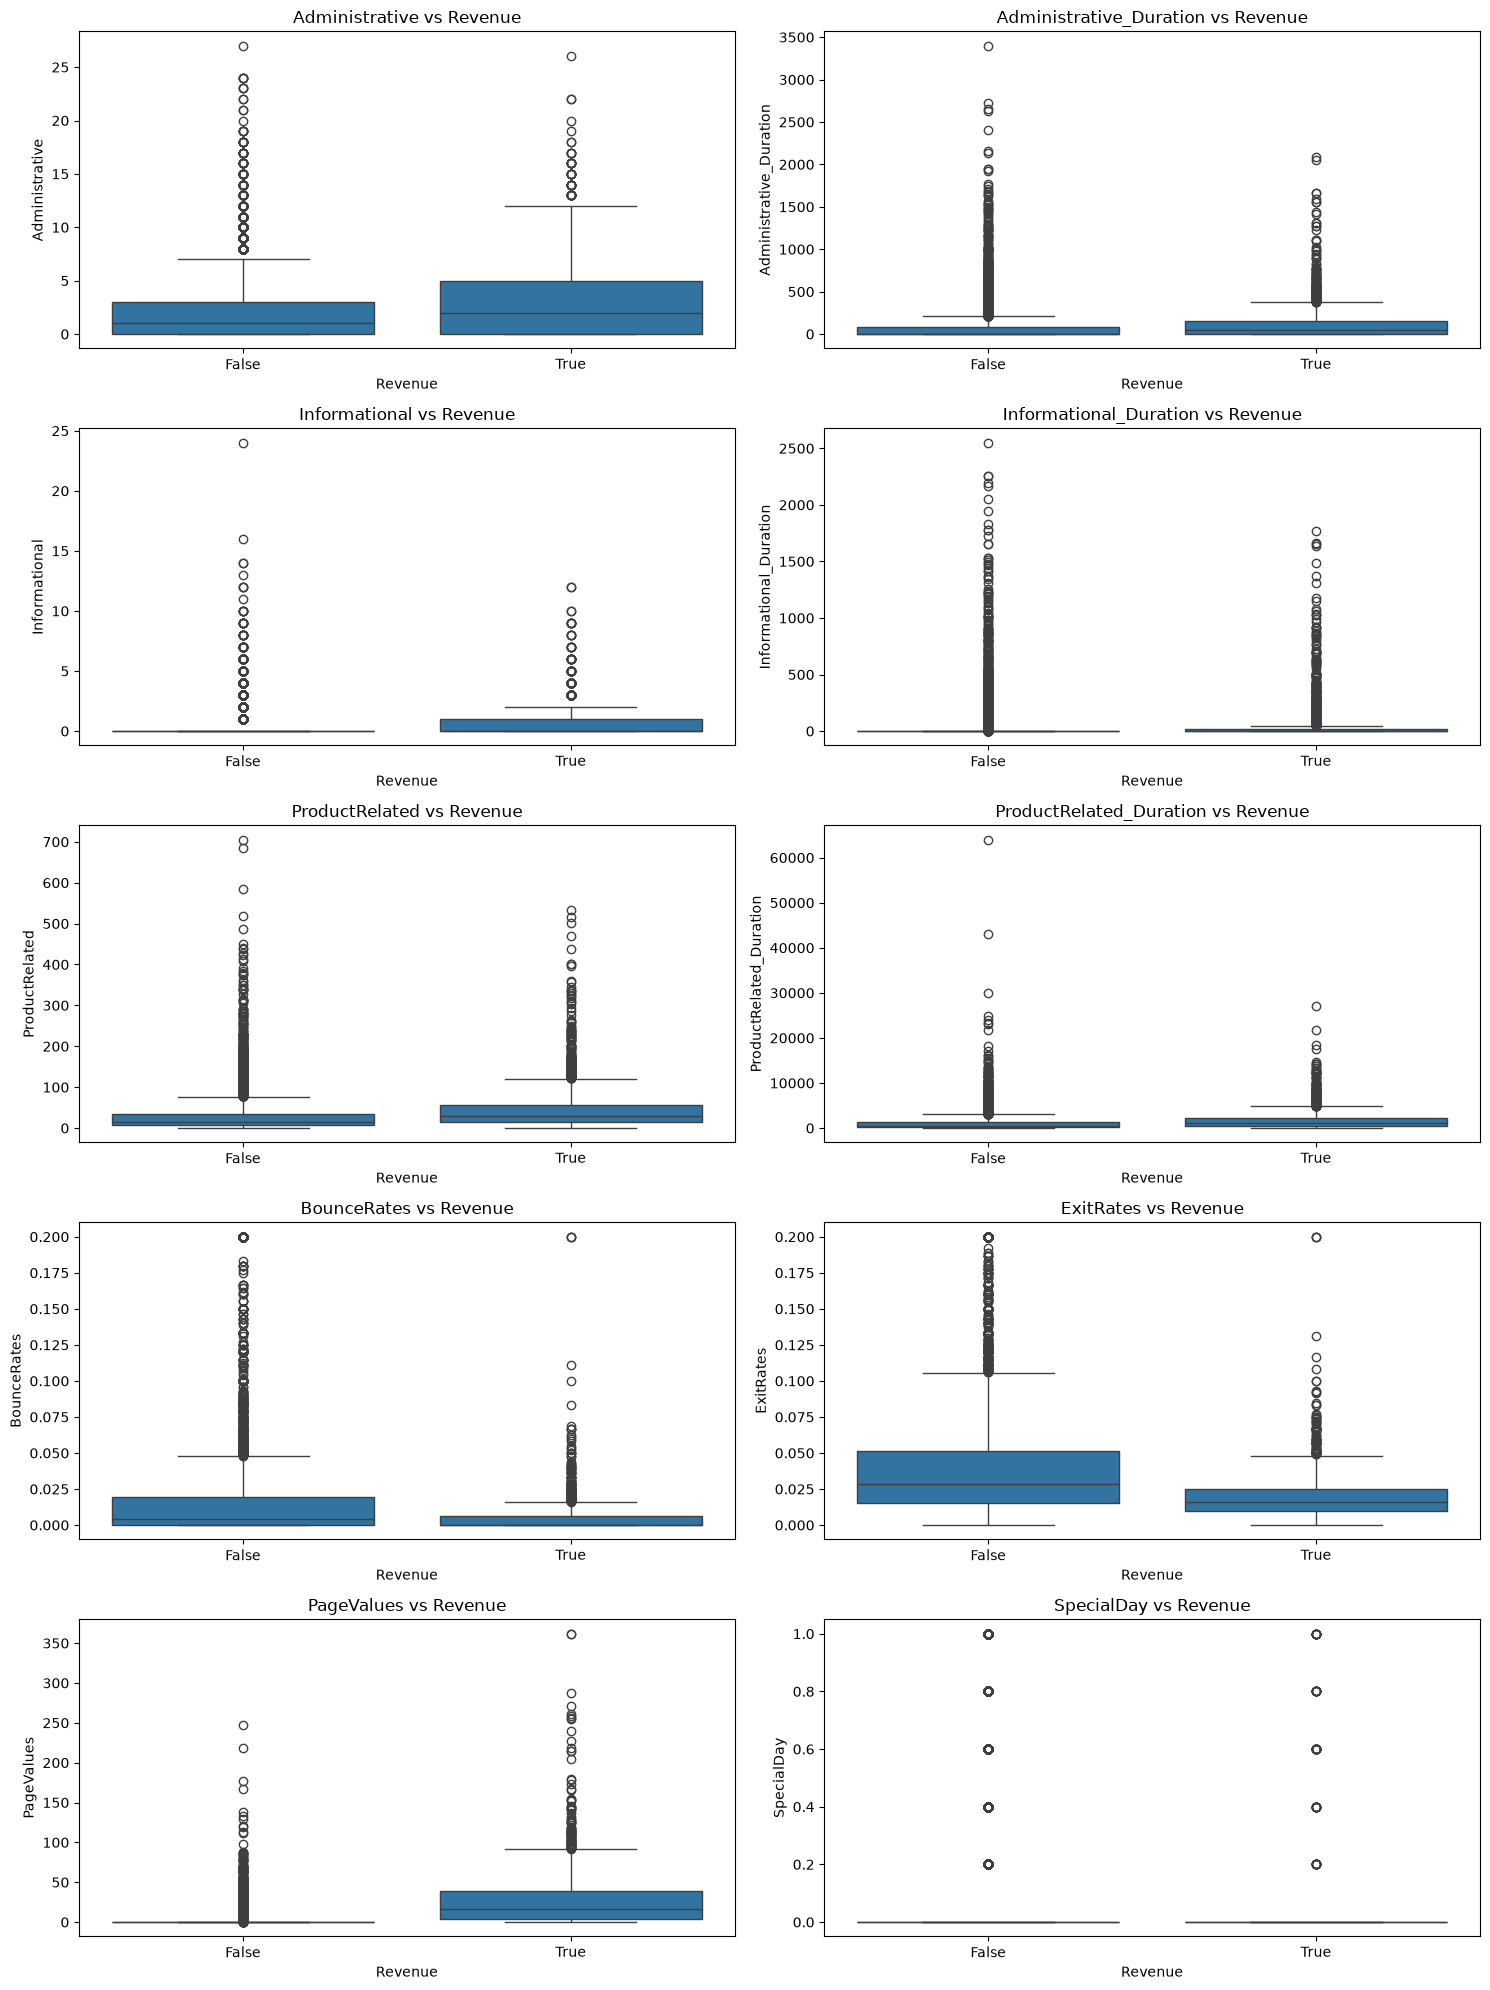

In [30]:
fig, axes = plt.subplots(5, 2, figsize=(15, 20))

for ax, col in zip(axes.flatten(), numeric_columns):
    sns.boxplot(data=df, x='Revenue', y=col, ax=ax)
    ax.set_title(f'{col} vs Revenue')

plt.tight_layout()
plt.show()

In [32]:
for col in categorical_columns:
    print(df[col].value_counts())

Month
May     3329
Nov     2982
Mar     1860
Dec     1706
Oct      549
Sep      448
Aug      433
Jul      432
June     285
Feb      181
Name: count, dtype: int64
OperatingSystems
2    6541
1    2549
3    2530
4     478
8      75
6      19
7       7
5       6
Name: count, dtype: int64
Browser
2     7883
1     2427
4      731
5      465
6      174
10     163
8      135
3      105
13      56
7       49
12      10
11       6
9        1
Name: count, dtype: int64
Region
1    4714
3    2379
4    1171
2    1128
6     801
7     758
9     505
8     431
5     318
Name: count, dtype: int64
TrafficType
2     3911
1     2388
3     2013
4     1066
13     728
10     450
6      443
8      343
5      260
11     247
20     193
9       41
7       40
15      37
19      17
14      13
18      10
16       3
12       1
17       1
Name: count, dtype: int64
VisitorType
Returning_Visitor    10431
New_Visitor           1693
Other                   81
Name: count, dtype: int64
Weekend
False    9346
True     2859
Na

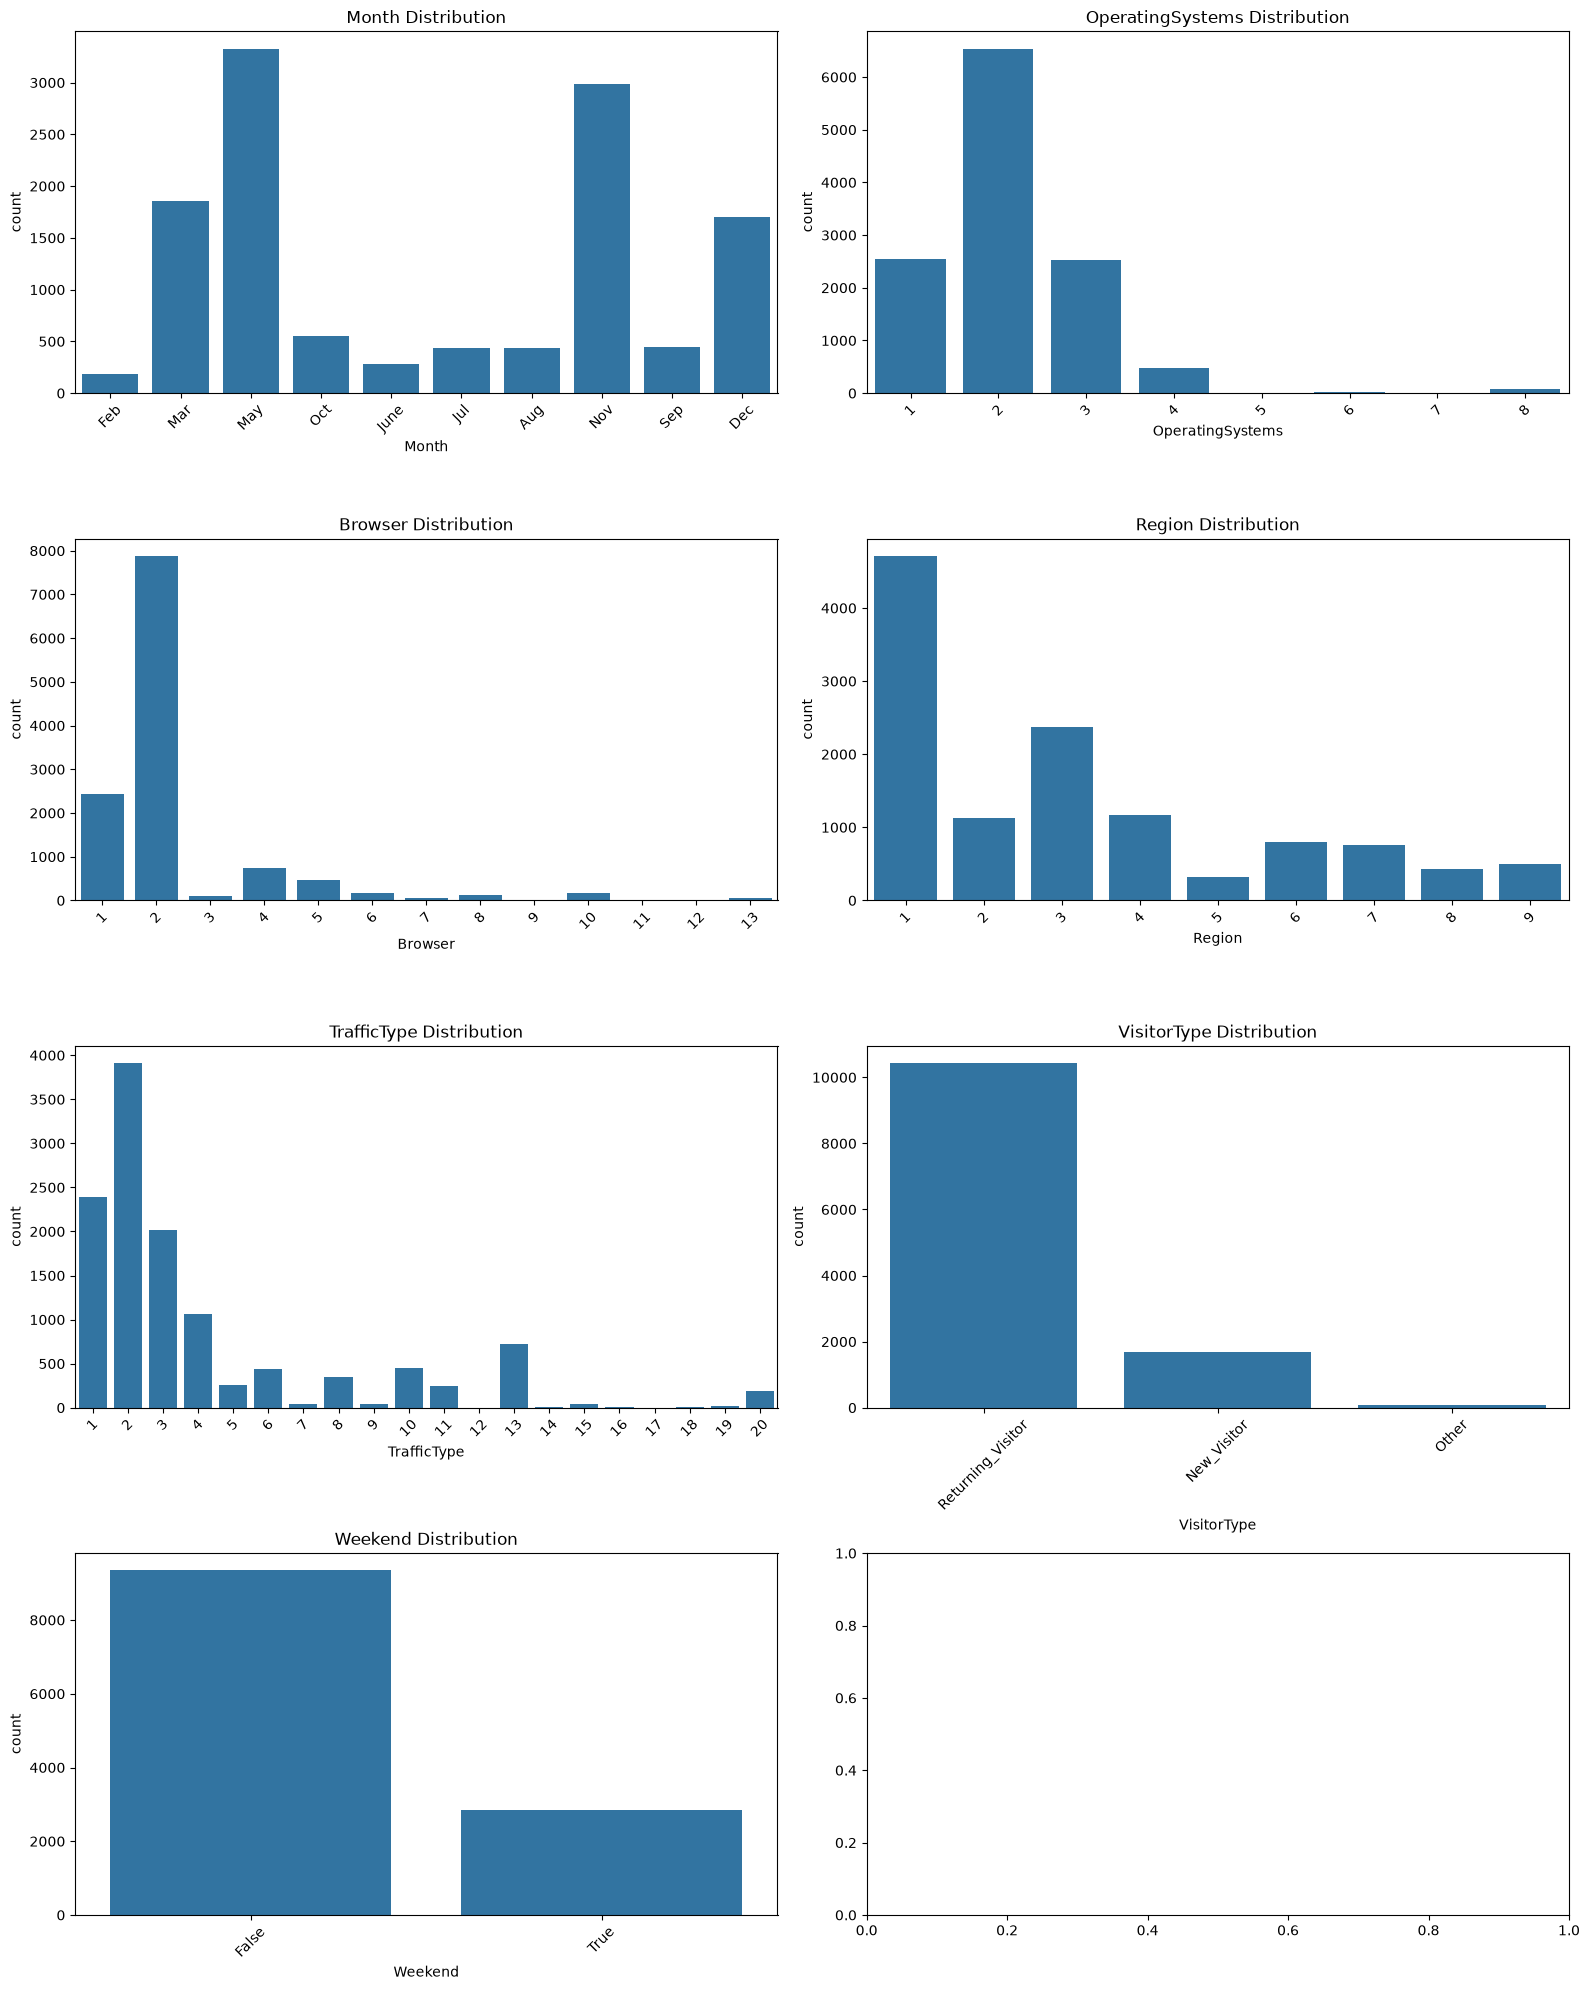

In [33]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))

for ax, col in zip(axes.flatten(), categorical_columns):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f'{col} Distribution')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [34]:
purchase_rate = df.groupby('VisitorType')['Revenue'].mean() * 100

print(purchase_rate)

VisitorType
New_Visitor          24.926167
Other                19.753086
Returning_Visitor    14.092609
Name: Revenue, dtype: float64


In [35]:
purchase_rate_weekend = df.groupby('Weekend')['Revenue'].mean() * 100

print(purchase_rate_weekend)

Weekend
False    15.075968
True     17.453655
Name: Revenue, dtype: float64


In [36]:
purchase_rate_month = df.groupby('Month')['Revenue'].mean() * 100

print(purchase_rate_month)

Month
Aug     17.551963
Dec     12.661196
Feb      1.657459
Jul     15.277778
June    10.175439
Mar     10.322581
May     10.964254
Nov     25.486251
Oct     20.947177
Sep     19.196429
Name: Revenue, dtype: float64


In [38]:
monthly_sessions = df['Month'].value_counts()

print(monthly_sessions)

Month
May     3329
Nov     2982
Mar     1860
Dec     1706
Oct      549
Sep      448
Aug      433
Jul      432
June     285
Feb      181
Name: count, dtype: int64


In [39]:
purchase_rate_os = df.groupby('OperatingSystems')['Revenue'].mean() * 100

print(purchase_rate_os)

OperatingSystems
1    14.868576
2    17.657850
3    10.592885
4    17.782427
5    16.666667
6    10.526316
7    14.285714
8    22.666667
Name: Revenue, dtype: float64


In [40]:
purchase_rate_browser = df.groupby('Browser')['Revenue'].mean() * 100

print(purchase_rate_browser)

Browser
1     15.039143
2     15.514398
3      4.761905
4     17.783858
5     18.494624
6     11.494253
7     12.244898
8     15.555556
9      0.000000
10    19.631902
11    16.666667
12    30.000000
13    28.571429
Name: Revenue, dtype: float64


In [41]:
purchase_rate_region = df.groupby('Region')['Revenue'].mean() * 100

print(purchase_rate_region)

Region
1    16.355537
2    16.666667
3    14.670029
4    14.944492
5    16.352201
6    13.982522
7    15.699208
8    12.993039
9    17.029703
Name: Revenue, dtype: float64


In [42]:
purchase_rate_traffic = df.groupby('TrafficType')['Revenue'].mean() * 100

print(purchase_rate_traffic)

TrafficType
1     10.971524
2     21.656865
3      8.941878
4     15.478424
5     21.538462
6     11.963883
7     30.000000
8     27.696793
9      9.756098
10    20.000000
11    19.028340
12     0.000000
13     5.906593
14    15.384615
15     0.000000
16    33.333333
17     0.000000
18     0.000000
19     5.882353
20    25.906736
Name: Revenue, dtype: float64


In [43]:
df.groupby('Revenue')['PageValues'].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10297.0,1.999985,9.124701,0.0,0.000000,0.000000,0.000000,246.758590
True,1908.0,27.264518,35.191954,0.0,3.641144,16.758134,38.897742,361.763742
